# **CS 5361/6361 Machine Learning**

**Linear Regression**

**Author:** [Olac Fuentes](http://www.cs.utep.edu/ofuentes/)<br>
**Last modified:** 2/25/2026<br>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
from sklearn.metrics import accuracy_score, confusion_matrix,mean_squared_error,mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.datasets import fetch_california_housing

# **Linear regression for the Housing dataset.**

In [ ]:
!ls

sample_data


In [ ]:
dataset = fetch_california_housing()
x = dataset.data
y = dataset.target
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=5361)

model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)
print('Mean squared error = {:.5f}'.format(mean_squared_error(pred,y_test)))
print('Mean absolute error =  {:.5f}'.format(mean_absolute_error(pred,y_test)))

print(model.coef_)
print(model.intercept_)

Mean squared error = 0.54565
Mean absolute error =  0.54147
[ 4.47022152e-01  9.31480965e-03 -1.26107922e-01  6.74080266e-01
 -4.27214102e-06 -3.94060963e-03 -4.14203716e-01 -4.28602827e-01]
-36.45487156115954


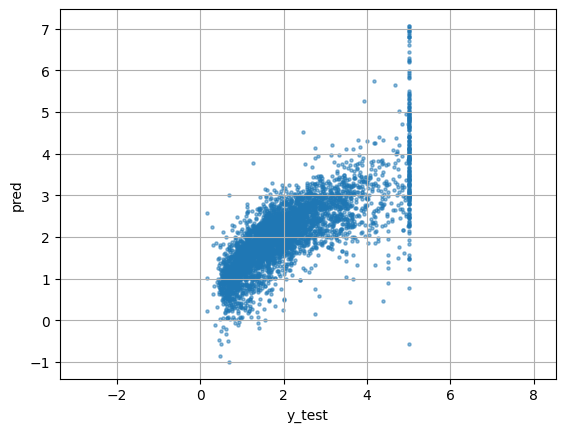

In [ ]:
plt.scatter(y_test,pred,s=5,alpha=0.5)
plt.xlabel("y_test")
plt.ylabel("pred")
plt.axis('equal')
plt.grid(True)
plt.show()

We can clip the prediction to be in the [min(y_train), max(y_train)] range.

Mean squared error = 0.52512
Mean absolute error =  0.52926


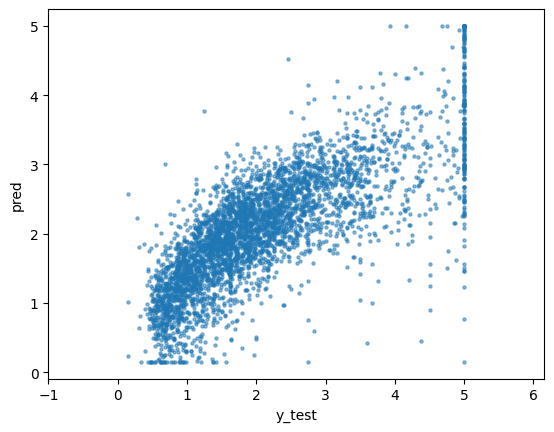

In [ ]:
pred = model.predict(X_test)
pred = np.clip(pred, np.min(y_train),np.max(y_train))
print('Mean squared error = {:.5f}'.format(mean_squared_error(pred,y_test)))
print('Mean absolute error =  {:.5f}'.format(mean_absolute_error(pred,y_test)))

plt.scatter(y_test,pred,s=5,alpha=0.5)
plt.xlabel("y_test")
plt.ylabel("pred")
plt.axis('equal')
plt.show()

Adding quadratic features

Mean squared error = 0.50562
Mean absolute error =  0.52336


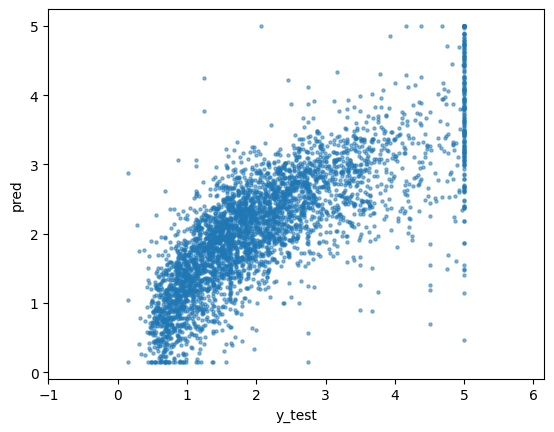

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=5361)

X_train = np.hstack((X_train,X_train**2))
X_test = np.hstack((X_test,X_test**2))
model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)
pred = np.clip(pred, np.min(y_train),np.max(y_train))
print('Mean squared error = {:.5f}'.format(mean_squared_error(pred,y_test)))
print('Mean absolute error =  {:.5f}'.format(mean_absolute_error(pred,y_test)))

plt.scatter(y_test,pred,s=5,alpha=0.5)
plt.xlabel("y_test")
plt.ylabel("pred")
plt.axis('equal')
plt.show()



Mean squared error = 0.50562
Mean absolute error =  0.52336


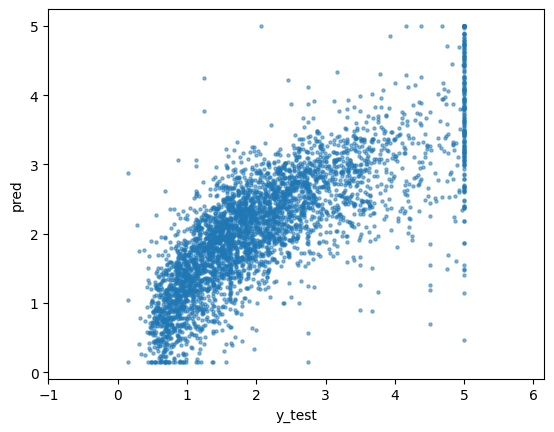

In [ ]:
from sklearn.preprocessing import MinMaxScaler

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=5361)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = np.hstack((X_train,X_train**2))
X_test = np.hstack((X_test,X_test**2))
model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)
pred = np.clip(pred, np.min(y_train),np.max(y_train))
print('Mean squared error = {:.5f}'.format(mean_squared_error(pred,y_test)))
print('Mean absolute error =  {:.5f}'.format(mean_absolute_error(pred,y_test)))

plt.scatter(y_test,pred,s=5,alpha=0.5)
plt.xlabel("y_test")
plt.ylabel("pred")
plt.axis('equal')
plt.show()


# **Linear regression for the particles dataset.**

In [ ]:
from google.colab import files


In [ ]:
files.upload()
!ls

sample_data


In [ ]:
!ls

sample_data


In [ ]:
PX = np.load('particles_X.npy')
Py = np.load('particles_y.npy')
print(PX.shape)
print(Py.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'particles_X.npy'

In [ ]:
print(f'{np.amin(PX,axis=0) = }')
print(f'{np.amax(PX,axis=0) = }')
print(f'{np.mean(PX,axis=0) = }')
print(f'{np.std(PX,axis=0) = }')

Now, using the sklearn implementation:

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(PX, Py, test_size=0.2,  random_state=4361)
print('X_train.shape =',X_train.shape)
model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)
print('Training mean squared error = {:.5f}'.format(mean_squared_error(model.predict(X_train),y_train)))
print('Mean squared error = {:.5f}'.format(mean_squared_error(pred,y_test)))

Plotting prediction vs correct values

In [ ]:
plt.scatter(y_test,pred,s=5,alpha=0.5)
plt.xlabel("y_test")
plt.ylabel("pred")
plt.axis('equal')
plt.grid(True)
plt.show()


Adding preprocessing

In [ ]:
from sklearn.preprocessing import MinMaxScaler

X_train, X_test, y_train, y_test = train_test_split(PX, Py, test_size=0.2,  random_state=4361)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print('X_train.shape =',X_train.shape)
model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)
plt.figure()
plt.plot(y_test,pred,'.')
plt.grid(True)
print('Training mean squared error = {:.5f}'.format(mean_squared_error(model.predict(X_train),y_train)))
print('Mean squared error = {:.5f}'.format(mean_squared_error(pred,y_test)))

Including the squares of all features as additional features.

In [ ]:
np.min(X_train,axis=0)

In [ ]:
np.max(X_train,axis=0)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(PX, Py, test_size=0.2,  random_state=4361)

X_train = np.hstack((X_train,X_train**2))
X_test = np.hstack((X_test,X_test**2))
print('X_train.shape =',X_train.shape)
model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)
plt.figure()
plt.plot(y_test,pred,'.')
plt.grid(True)
print('Training mean squared error = {:.5f}'.format(mean_squared_error(model.predict(X_train),y_train)))
print('Mean squared error = {:.5f}'.format(mean_squared_error(pred,y_test)))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(PX, Py, test_size=0.2,  random_state=4361)
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = np.hstack((X_train,X_train**2))
X_test = np.hstack((X_test,X_test**2))
print('X_train.shape =',X_train.shape)
model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)
plt.figure()
plt.plot(y_test,pred,'.')
plt.grid(True)

print('Training mean squared error = {:.5f}'.format(mean_squared_error(model.predict(X_train),y_train)))
print('Mean squared error = {:.5f}'.format(mean_squared_error(pred,y_test)))



Including the products of every pair of features as additional features.

Original features:  $X_0,X_1,X_2,X_3,X_4$

Additional features: $X_0*X_0,X_0*X_1,X_0*X_2,X_0*X_3,X_0*X_4, X_1*X_2, X_1*X_3 ..., X_3*X_4$



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(PX, Py, test_size=0.2,  random_state=4361)
for i in range(5):
  for j in range(i,5):
    X_train = np.hstack((X_train,X_train[:,i:i+1]*X_train[:,j:j+1]))
    X_test = np.hstack((X_test,X_test[:,i:i+1]*X_test[:,j:j+1]))
    print('adding',i,j)

print('X_train.shape =',X_train.shape)
model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)
print('Training mean squared error = {:.5f}'.format(mean_squared_error(model.predict(X_train),y_train)))
print('Mean squared error = {:.5f}'.format(mean_squared_error(pred,y_test)))
plt.figure()
plt.plot(y_test,pred,'.')
plt.grid(True)
print(model.coef_)
print(model.intercept_)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(PX, Py, test_size=0.2,  random_state=4361)
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

for i in range(5):
  for j in range(i,5):
    X_train = np.hstack((X_train,X_train[:,i:i+1]*X_train[:,j:j+1]))
    X_test = np.hstack((X_test,X_test[:,i:i+1]*X_test[:,j:j+1]))
    print('adding',i,j)

print('X_train.shape =',X_train.shape)
model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)
print('Training mean squared error = {:.5f}'.format(mean_squared_error(model.predict(X_train),y_train)))
print('Mean squared error = {:.5f}'.format(mean_squared_error(pred,y_test)))
plt.figure()
plt.plot(y_test,pred,'.')
plt.grid(True)
print(model.coef_)
print(model.intercept_)